# League of Legends Win Prediction from 15-Minute Match Data

## League of Legends SoloQ matches at 15 minutes 2024

The dataset comes from the MOBA game League of Legends. It contains ranked solo-queue matches from 2024 played between Emerald and Diamond rank, and every feature describes only the first 15 minutes of a match. The goal of this project is to train several classification models that predict whether the blue team wins or loses, i.e. whether the blue or the red side takes the game.

Source: [League of Legends SoloQ matches at 15 minutes 2024](https://www.kaggle.com/datasets/karlorusovan/league-of-legends-soloq-matches-at-10-minutes-2024/data)

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from plotly.offline import init_notebook_mode, iplot
import plotly.express as px

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder, RobustScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

# scikit-learn >= 1.8 deprecates LogisticRegression's `penalty` argument; the tuning grid
# still searches over it, so silence this specific warning to keep results unchanged
warnings.filterwarnings('ignore', message=".*'penalty' was deprecated.*", category=FutureWarning)

# Dataset Description

- **matchId** – League of Legends match ID
- **blueTeamControlWardsPlaced** – number of control (pink) wards placed by the blue team (may contain outliers when a team "trolls" late in the game by buying and placing many wards)
- **blueTeamWardsPlaced** – total number of wards of all types placed by the blue team (control wards, yellow trinket, ghost poro trinket, etc.)
- **blueTeamTotalKills** – total champion kills by the blue team; killing an enemy champion grants gold and experience
- **blueTeamDragonKills** – total dragons killed by the blue team; dragons grant permanent buffs, and the fourth dragon grants the Dragon Soul
- **blueTeamHeraldKills** – total Rift Herald kills by the blue team; the Herald helps destroy enemy structures (towers, inhibitors, nexus) and push a lane
- **blueTeamTowersDestroyed** – number of towers destroyed by the blue team; towers are defensive structures in each lane
- **blueTeamInhibitorsDestroyed** – number of inhibitors destroyed by the blue team; destroying an inhibitor spawns super minions
- **blueTeamTurretPlatesDestroyed** – number of turret plates destroyed by the blue team; plates protect a tower, grant gold when destroyed and fall off after minute 14
- **blueTeamFirstBlood** – 1 if the blue team got first blood, 0 if the red team did; first blood grants bonus gold
- **blueTeamMinionsKilled** – total minions killed by the blue team; minions are one of the main sources of gold and experience
- **blueTeamJungleMinions** – total jungle monsters killed by the blue team; they grant gold, and the experience goes mainly to the jungler
- **blueTeamTotalGold** – total gold earned by the blue team (from structures, kills, assists, minions, etc.)
- **blueTeamXp** – total experience of the blue team; reflects time spent in lane and the number of champions killed
- **blueTeamTotalDamageToChamps** – total damage dealt by the blue team to enemy champions
- **blueWin** – 1 if the blue team won, 0 if the red team won

*The same attributes (except matchID, blueTeamFirstBlood and blueWin) are also available for the red team.*

The dataset has roughly 25k rows and 29 columns.

In [2]:
df = pd.read_csv('data/match_data_v5.csv'
                , names=['matchID','blueTeamControlWardsPlaced', 'blueTeamWardsPlaced', 'blueTeamTotalKills', 'blueTeamDragonKills', 'blueTeamHeraldKills',
                        'blueTeamTowersDestroyed', 'blueTeamInhibitorsDestroyed', 'blueTeamTurretPlatesDestroyed', 'blueTeamFirstBlood', 'blueTeamMinionsKilled',
                        'blueTeamJungleMinions', 'blueTeamTotalGold', 'blueTeamXp', 'blueTeamTotalDamageToChamps', 'redTeamControlWardsPlaced', 'redTeamWardsPlaced',
                        'redTeamTotalKills', 'redTeamDragonKills', 'redTeamHeraldKills', 'redTeamTowersDestroyed', 'redTeamInhibitorsDestroyed', 'redTeamTurretPlatesDestroyed',
                        'redTeamMinionsKilled', 'redTeamJungleMinions', 'redTeamTotalGold', 'redTeamXp', 'redTeamTotalDamageToChamps', 'blueWin', 'extra'], header=0)

pd.set_option('display.max_columns', None)
df = df.drop('extra', axis=1)
df.head()

,matchID,blueTeamControlWardsPlaced,blueTeamWardsPlaced,blueTeamTotalKills,blueTeamDragonKills,blueTeamHeraldKills,blueTeamTowersDestroyed,blueTeamInhibitorsDestroyed,blueTeamTurretPlatesDestroyed,blueTeamFirstBlood,blueTeamMinionsKilled,blueTeamJungleMinions,blueTeamTotalGold,blueTeamXp,blueTeamTotalDamageToChamps,redTeamControlWardsPlaced,redTeamWardsPlaced,redTeamTotalKills,redTeamDragonKills,redTeamHeraldKills,redTeamTowersDestroyed,redTeamInhibitorsDestroyed,redTeamTurretPlatesDestroyed,redTeamMinionsKilled,redTeamJungleMinions,redTeamTotalGold,redTeamXp,redTeamTotalDamageToChamps,blueWin
0,EUW1_6882489515',2,23,4,2,0,0,0,7,0,388,106,23923,29798,21842,6,34,16,0,0,2,0,1,400,94,29637,32613,27239,1
1,EUW1_6882416210',2,46,12,1,0,1,0,10,0,348,98,27852,30530,35817,6,26,17,0,0,1,0,4,373,76,28970,30320,36585,0
2,EUW1_6881092720',2,19,13,0,0,0,0,11,0,331,96,28126,29501,38039,3,241,18,1,0,2,0,3,340,84,30510,29464,42984,0
3,EUW1_6879405717',3,28,8,0,1,1,0,9,1,355,84,27333,30466,31338,0,23,10,1,0,0,0,5,378,87,25157,31069,28229,0
4,EUW1_6879389461',3,30,11,1,1,1,0,7,0,370,100,27772,31066,26676,7,26,7,1,0,1,0,5,382,96,26052,29475,19245,1


# Data Preprocessing

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 24225 entries, 0 to 24224
Data columns (total 29 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   matchID                        24225 non-null  str  
 1   blueTeamControlWardsPlaced     24225 non-null  int64
 2   blueTeamWardsPlaced            24225 non-null  int64
 3   blueTeamTotalKills             24225 non-null  int64
 4   blueTeamDragonKills            24225 non-null  int64
 5   blueTeamHeraldKills            24225 non-null  int64
 6   blueTeamTowersDestroyed        24225 non-null  int64
 7   blueTeamInhibitorsDestroyed    24225 non-null  int64
 8   blueTeamTurretPlatesDestroyed  24225 non-null  int64
 9   blueTeamFirstBlood             24225 non-null  int64
 10  blueTeamMinionsKilled          24225 non-null  int64
 11  blueTeamJungleMinions          24225 non-null  int64
 12  blueTeamTotalGold              24225 non-null  int64
 13  blueTeamXp                 

The only categorical variable in the dataset is matchID. Next, let's look at the feature distributions.

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
blueTeamControlWardsPlaced,24225.0,3.610815,2.018622,0.0,2.0,3.0,5.0,37.0
blueTeamWardsPlaced,24225.0,41.362023,43.471913,9.0,25.0,29.0,35.0,603.0
blueTeamTotalKills,24225.0,12.792487,4.910510,0.0,9.0,12.0,16.0,38.0
blueTeamDragonKills,24225.0,0.737833,0.722126,0.0,0.0,1.0,1.0,2.0
blueTeamHeraldKills,24225.0,0.123591,0.329247,0.0,0.0,0.0,0.0,2.0
blueTeamTowersDestroyed,24225.0,0.654902,0.885749,0.0,0.0,0.0,1.0,10.0
blueTeamInhibitorsDestroyed,24225.0,0.002023,0.054101,0.0,0.0,0.0,0.0,2.0
blueTeamTurretPlatesDestroyed,24225.0,8.915789,3.083976,0.0,7.0,9.0,11.0,22.0
blueTeamFirstBlood,24225.0,0.503860,0.499995,0.0,0.0,1.0,1.0,1.0
blueTeamMinionsKilled,24225.0,349.240578,31.339593,194.0,329.0,350.0,371.0,465.0


In [5]:
df.isnull().sum()

matchID                          0
blueTeamControlWardsPlaced       0
blueTeamWardsPlaced              0
blueTeamTotalKills               0
blueTeamDragonKills              0
blueTeamHeraldKills              0
blueTeamTowersDestroyed          0
blueTeamInhibitorsDestroyed      0
blueTeamTurretPlatesDestroyed    0
blueTeamFirstBlood               0
blueTeamMinionsKilled            0
blueTeamJungleMinions            0
blueTeamTotalGold                0
blueTeamXp                       0
blueTeamTotalDamageToChamps      0
redTeamControlWardsPlaced        0
redTeamWardsPlaced               0
redTeamTotalKills                0
redTeamDragonKills               0
redTeamHeraldKills               0
redTeamTowersDestroyed           0
redTeamInhibitorsDestroyed       0
redTeamTurretPlatesDestroyed     0
redTeamMinionsKilled             0
redTeamJungleMinions             0
redTeamTotalGold                 0
redTeamXp                        0
redTeamTotalDamageToChamps       0
blueWin             

There are no missing values, so we can move on to plotting the feature distributions.

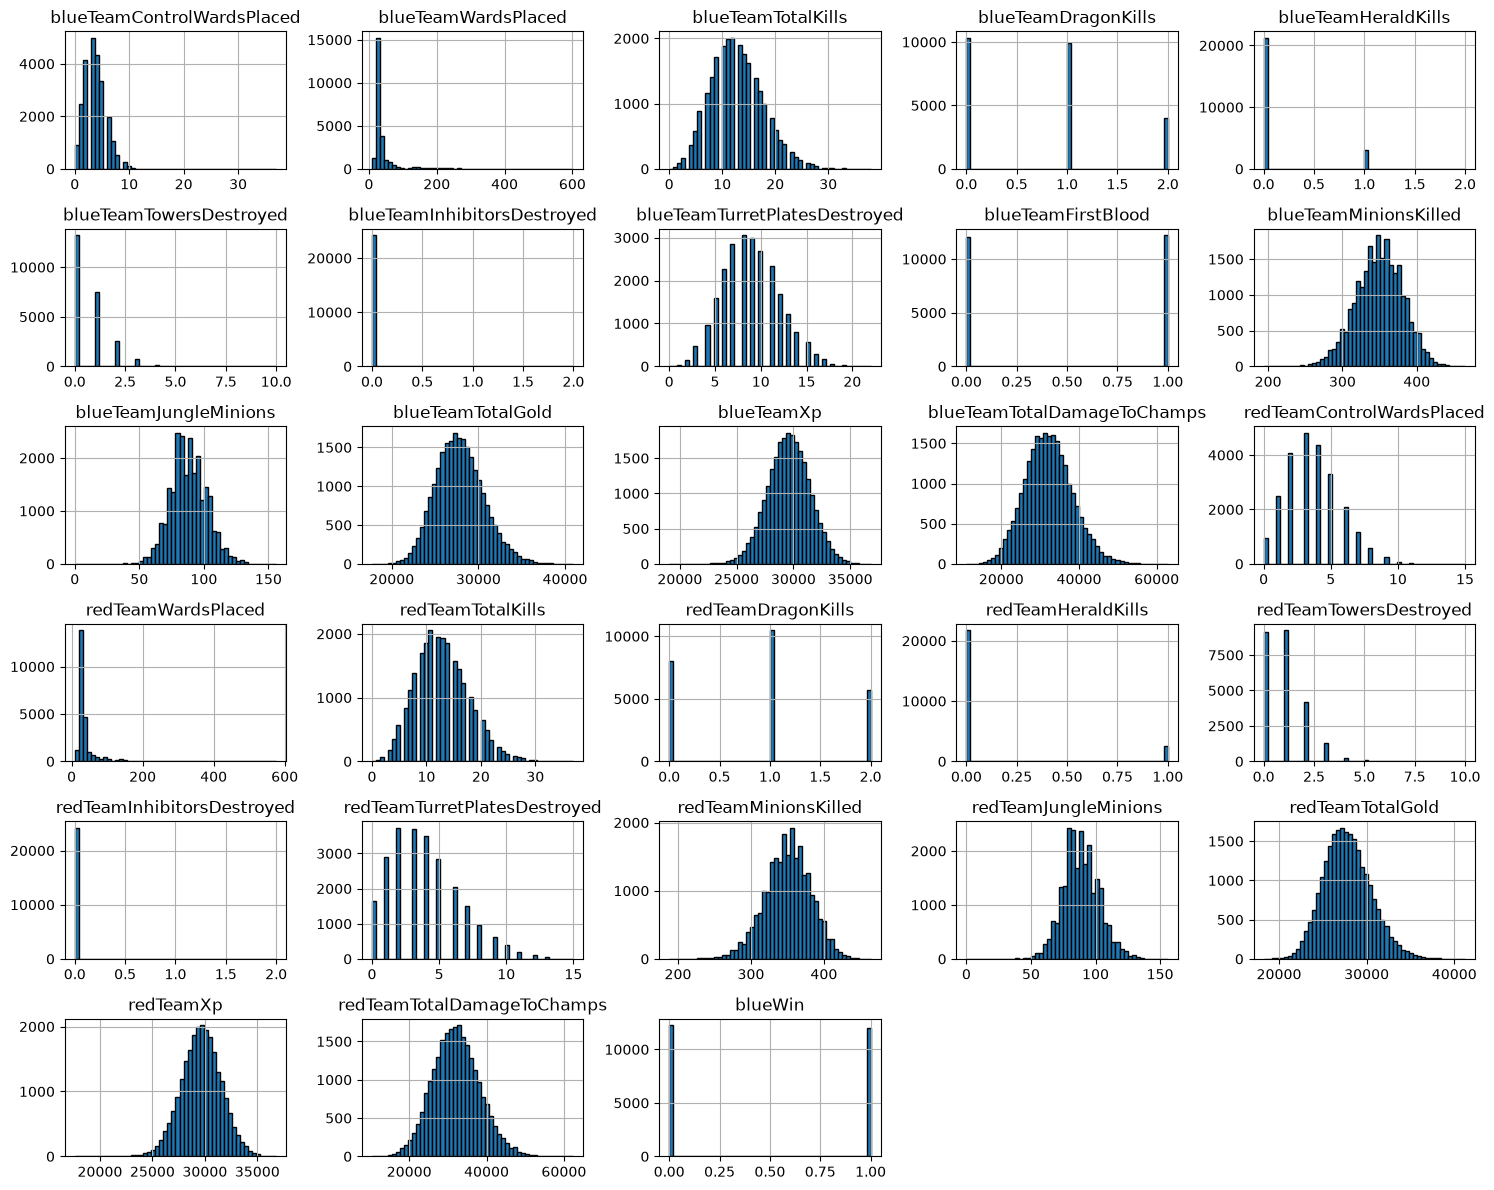

In [6]:
df.hist(bins=50, figsize=(15, 12), edgecolor='black')
plt.tight_layout()
plt.show()

The feature distributions look reasonable. Next, a closer look at the distribution of the target variable **blueWin**.

In [7]:
iplot(px.pie(df['blueWin'].value_counts(), names=['Red team', 'Blue team'],
             values='count', color_discrete_sequence=['red', 'blue']).update_traces(textinfo='label+percent'))

The target classes are almost perfectly balanced. In theory both sides should have a 50% win rate, but the League of Legends community has long known that blue side generally wins about 1% more often. Here blue side is about 0.5% below 50% instead. This is not a concern: it is only a sample, and it covers just two divisions.

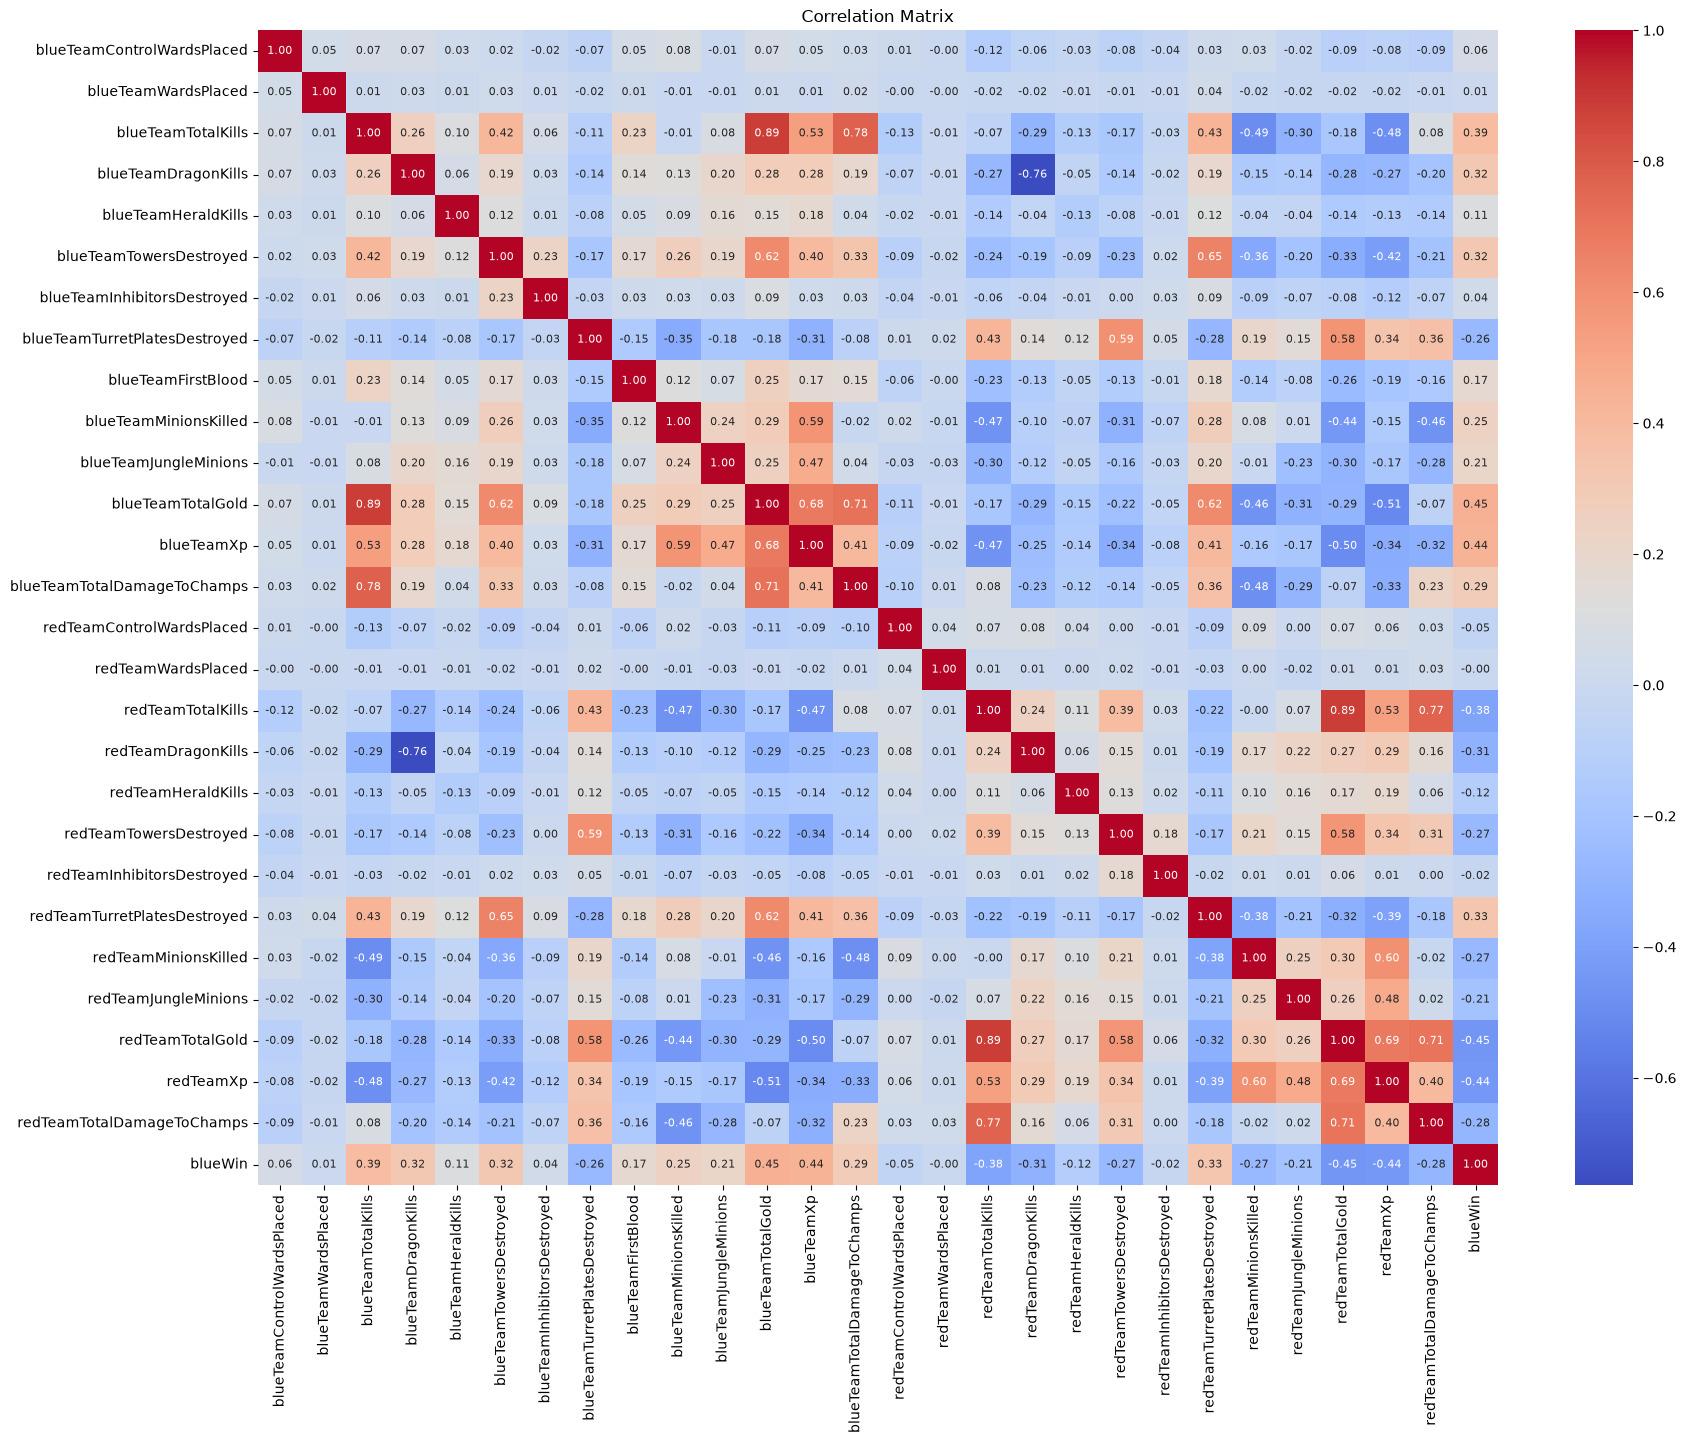

In [8]:
numeric_df = df.select_dtypes(include=[np.number])

plt.figure(figsize=(20, 15))
sns.heatmap(numeric_df.corr(), annot=True, fmt='.2f', cmap='coolwarm', annot_kws={"size": 8})
plt.title('Correlation Matrix')
plt.show()

The correlation matrix shows several patterns that are well known in the LoL community. One example is the negative correlation between red-team dragon kills and blue-team dragon kills. This makes sense: once one team takes a dragon, the other team cannot get it. Both teams keep contesting dragons until one of them is the first to secure 4. After that, only the stronger Elder Dragon spawns later in the game, so the other team can no longer catch up on regular dragons.

Another correlation that follows from the game mechanics links a team's gold, XP and damage dealt to the enemy with its total kills. A team with an advantage (more gold, higher levels) deals more damage and puts more pressure on the opponent, and as a result usually gets more kills.

Finally, the matrix shows a relationship between team gold and the number of enemy towers or turret plates destroyed. Until minute 14, towers are tougher, but each one carries 5 plates. Destroying a plate before minute 14 grants the team bonus gold.

Given the column semantics, the **turretPlatesDestroyed** columns have to be swapped between the two teams. In the raw data, **blueTeamTurretPlatesDestroyed** means how many plates the blue team *lost*. After the swap it means how many plates the blue team destroyed. Another issue is invalid plate counts: a team can destroy at most 15 plates (3 outer towers, one per lane × 5 plates = 15).

In [9]:
# Swap the plate columns so each one counts plates destroyed BY that team
df = df.rename(columns={'blueTeamTurretPlatesDestroyed': 'redTeamTurretPlatesDestroyed', 'redTeamTurretPlatesDestroyed': 'blueTeamTurretPlatesDestroyed'})


# Drop rows with impossible values (more than 15 plates, more than 2 Herald kills)
remove1 = df[df['blueTeamTurretPlatesDestroyed'] > 15].index
df = df.drop(remove1)
remove2 = df[df['redTeamTurretPlatesDestroyed'] > 15].index
df = df.drop(remove2)
remove3 = df[df['blueTeamHeraldKills'] > 2].index
df = df.drop(remove3)
print ("Dataset shape after removing invalid rows:", df.shape)

Dataset shape after removing invalid rows: (23685, 29)


With the data reviewed and cleaned, it is split into a training and a test set. I used an 80:20 split and also dropped matchID, which carries no predictive information.

Using `stratify` ensures that the training and test sets have the same class ratio.

In [10]:
X = df.drop(columns=["matchID", "blueWin"])
y = df["blueWin"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((18948, 27), (4737, 27), (18948,), (4737,))

Next, the scaler is fitted on the training data only and then used to transform the test data. This avoids data leakage and keeps the evaluation fair and valid.

In [11]:
# Columns with a roughly Gaussian distribution (StandardScaler)
gaussian_cols = [
    'blueTeamTotalKills', 'redTeamTotalKills',
    'blueTeamTurretPlatesDestroyed', 'redTeamTurretPlatesDestroyed',
    'blueTeamMinionsKilled', 'redTeamMinionsKilled',
    'blueTeamJungleMinions', 'redTeamJungleMinions',
    'blueTeamTotalGold', 'redTeamTotalGold',
    'blueTeamXp', 'redTeamXp',
    'blueTeamTotalDamageToChamps', 'redTeamTotalDamageToChamps'
]

# Columns with a heavily skewed distribution and outliers (RobustScaler)
robust_cols = [
    'blueTeamWardsPlaced', 'redTeamWardsPlaced',
    'blueTeamControlWardsPlaced', 'redTeamControlWardsPlaced',
    'blueTeamTowersDestroyed', 'redTeamTowersDestroyed',
    'blueTeamInhibitorsDestroyed', 'redTeamInhibitorsDestroyed',
]

preprocessor = ColumnTransformer(
    transformers=[
        # Apply StandardScaler to the Gaussian columns
        ('std', StandardScaler(), gaussian_cols),

        # Apply RobustScaler to the skewed columns
        ('rob', RobustScaler(), robust_cols)
    ],
    # 'passthrough' keeps all remaining columns unchanged in the output
    remainder='passthrough'
)
scaler = preprocessor

X_train_scaled_array = scaler.fit_transform(X_train)
X_test_scaled_array = scaler.transform(X_test)


In [12]:
transformed_cols = gaussian_cols + robust_cols
all_cols = X_train.columns.tolist()
passthrough_cols = [col for col in all_cols if col not in transformed_cols]
feature_names = transformed_cols + passthrough_cols

X_train_scaled = pd.DataFrame(X_train_scaled_array, columns=feature_names)
X_test_scaled = pd.DataFrame(X_test_scaled_array, columns=feature_names)

In [13]:
column_name = 'blueTeamTotalKills'
print(f"Mean {column_name}: {X_train_scaled[column_name].mean():.4f}")
print(f"Std. dev. {column_name}: {X_train_scaled[column_name].std():.4f}")

column_name = 'blueTeamWardsPlaced'
print(f"Median {column_name}: {X_train_scaled[column_name].median():.4f}")
print(f"IQR {column_name}: {X_train_scaled[column_name].quantile(0.75) - X_train_scaled[column_name].quantile(0.25):.4f}")

Mean blueTeamTotalKills: 0.0000
Std. dev. blueTeamTotalKills: 1.0000
Median blueTeamWardsPlaced: 0.0000
IQR blueTeamWardsPlaced: 1.0000


# Decision Tree

A decision tree classifies samples using a tree structure. It learns a sequence of yes/no questions: each internal node tests one feature, and the decision moves down the tree until it reaches a leaf, which determines the predicted class.

## Decision Tree: Baseline

In [14]:
# Build and train the model
model_baseDT = DecisionTreeClassifier(random_state=42)
model_baseDT.fit(X_train_scaled, y_train)

# Predict on the test set
y_pred_baseDT = model_baseDT.predict(X_test_scaled)

Accuracy: 0.6691999155583703
              precision    recall  f1-score   support

           0       0.67      0.67      0.67      2360
           1       0.67      0.67      0.67      2377

    accuracy                           0.67      4737
   macro avg       0.67      0.67      0.67      4737
weighted avg       0.67      0.67      0.67      4737



<Figure size 700x500 with 0 Axes>

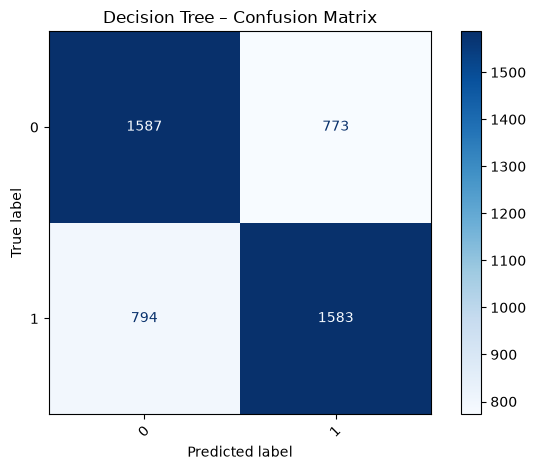

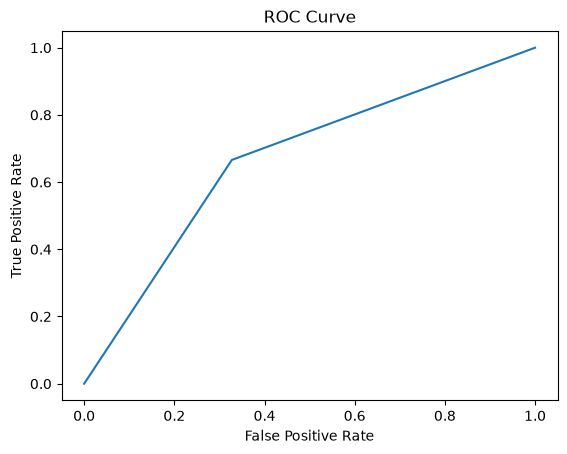

AUC: 0.6692115649265916


In [15]:
print("Accuracy:", accuracy_score(y_test, y_pred_baseDT))
print(classification_report(y_test, y_pred_baseDT))

plt.figure(figsize=(7,5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_baseDT,
    xticks_rotation=45,
    cmap="Blues"
)
plt.title("Decision Tree – Confusion Matrix")
plt.tight_layout()
plt.show()


y_prob = model_baseDT.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

print("AUC:", roc_auc_score(y_test, y_prob))


Without hyperparameter tuning, the decision tree reaches fairly poor accuracy of only ~0.67.
* Precision and recall: balanced for both classes (0 and 1), so the model shows no strong preference for either class.
* F1-score: around 0.67 for both classes, a consistent balance between precision and recall.
* AUC (Area Under the Curve): 0.67. The model separates the classes only moderately and is not much better than random guessing (AUC 0.5).

## Decision Tree: Tuning

| Parameter | What it does | Why it matters |
|----------|---------|-----------------|
| `max_depth` | Maximum depth of the tree | Limits complexity and prevents overfitting |
| `min_samples_split` | Minimum number of samples required to split a node | Prevents splitting into very small groups |
| `min_samples_leaf` | Minimum number of samples in a leaf | Ensures leaves are not too small |
| `max_leaf_nodes` | Maximum number of leaf nodes | Alternative to `max_depth`; limits tree size |
| `criterion` | Function that measures split quality (`gini` or `entropy`) | Affects how nodes are split |
| `class_weight` | Class weights (e.g. `"balanced"`) | Helps with imbalanced classes |
| `splitter` | Strategy for choosing the split (`best` or `random`) | Can affect performance and speed |

Gini: the probability that a randomly chosen sample would be misclassified if it were labeled randomly according to the class distribution in the node. The lower the Gini impurity, the purer the node.

Entropy: measures the uncertainty (information content) in a node. The lower the entropy, the less mixed the classes are.

In [16]:
param_grid_DT = {
    'max_depth': [None, 3, 5, 10, 15, 30, 40],
    'min_samples_split': [10, 15, 20],
    'min_samples_leaf': [1, 2, 4],
    'criterion': ['gini', 'entropy']
}


clf_DT = DecisionTreeClassifier(random_state=42)
model_tunedDT = RandomizedSearchCV(estimator=clf_DT, param_distributions=param_grid_DT, n_iter=30, cv=5, scoring='accuracy', n_jobs=-1, random_state=42)
model_tunedDT.fit(X_train_scaled, y_train)

print("Best parameters:", model_tunedDT.best_params_)
print("Best CV accuracy:", model_tunedDT.best_score_)

y_pred_tunedDT = model_tunedDT.predict(X_test_scaled)

Best parameters: {'min_samples_split': 20, 'min_samples_leaf': 4, 'max_depth': 5, 'criterion': 'gini'}
Best CV accuracy: 0.7398139594479506


Accuracy: 0.7264091196960102
              precision    recall  f1-score   support

           0       0.71      0.76      0.73      2360
           1       0.74      0.69      0.72      2377

    accuracy                           0.73      4737
   macro avg       0.73      0.73      0.73      4737
weighted avg       0.73      0.73      0.73      4737



<Figure size 700x500 with 0 Axes>

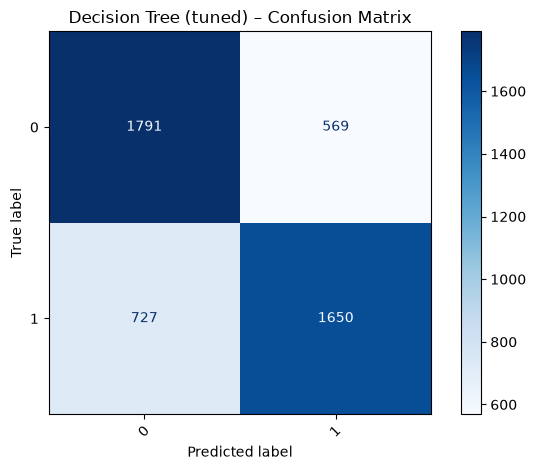

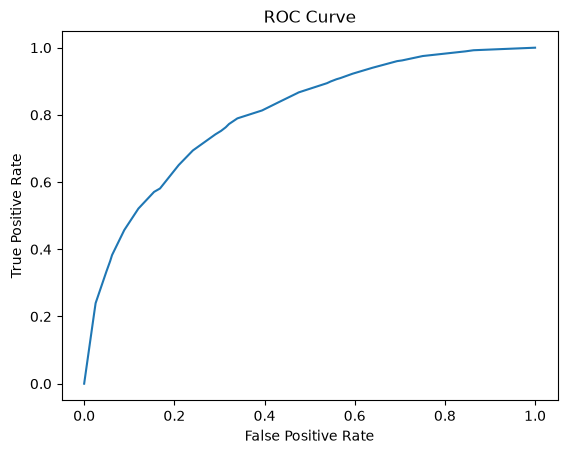

AUC: 0.8012249274473593


In [17]:
print("Accuracy:", accuracy_score(y_test, y_pred_tunedDT))
print(classification_report(y_test, y_pred_tunedDT))

plt.figure(figsize=(7,5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tunedDT,
    xticks_rotation=45,
    cmap="Blues"
)
plt.title("Decision Tree (tuned) – Confusion Matrix")
plt.tight_layout()
plt.show()


y_prob = model_tunedDT.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

print("AUC:", roc_auc_score(y_test, y_prob))

After tuning, the results are better and more acceptable, but still not good enough to reliably predict the outcome of a game.
* Accuracy: 72.6% – up from the baseline model (66.9%), indicating better overall classification.
* Precision & Recall: precision 0.71 (class 0) and 0.74 (class 1); recall 0.76 and 0.69. The tuned tree favors predicting a red-side win slightly more often than the baseline.
* F1-score: 0.73 and 0.72, so overall performance is still similar across classes.
* AUC: 0.801 – a clear improvement in class separation over the baseline AUC of 0.669, which is also visible in the ROC curve.
* Best CV accuracy: 74.0%.

Best parameters:
* criterion: gini
* max_depth: 5
* min_samples_leaf: 4
* min_samples_split: 20

# Random Forest

Random Forest is an ensemble model that combines many decision trees. Instead of relying on a single tree, it builds dozens to hundreds of trees, each trained on a slightly different sample of the data, and then takes a majority vote.

## Random Forest: Baseline

In [18]:
model_baseRF = RandomForestClassifier(random_state=42)
model_baseRF.fit(X_train_scaled, y_train)

y_pred_baseRF = model_baseRF.predict(X_test_scaled)

Accuracy: 0.7409753008233059
              precision    recall  f1-score   support

           0       0.74      0.74      0.74      2360
           1       0.74      0.74      0.74      2377

    accuracy                           0.74      4737
   macro avg       0.74      0.74      0.74      4737
weighted avg       0.74      0.74      0.74      4737



<Figure size 700x500 with 0 Axes>

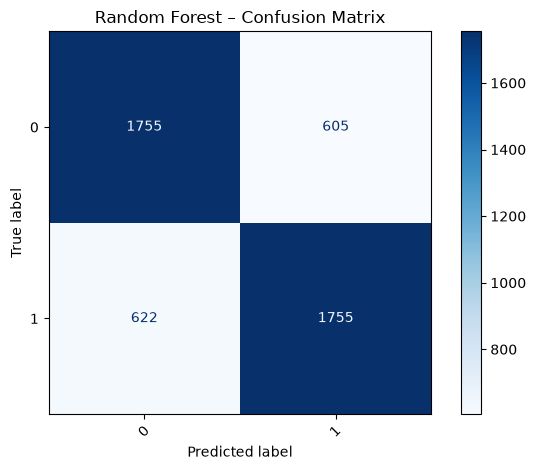

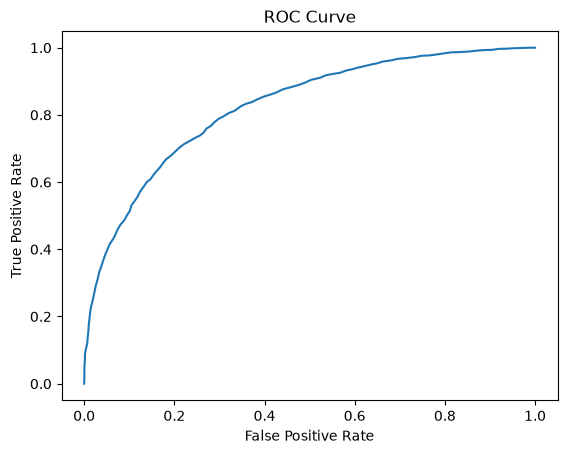

AUC: 0.8249858281696769


In [19]:
print("Accuracy:", accuracy_score(y_test, y_pred_baseRF))
print(classification_report(y_test, y_pred_baseRF))

plt.figure(figsize=(7,5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_baseRF,
    xticks_rotation=45,
    cmap="Blues"
)
plt.title("Random Forest – Confusion Matrix")
plt.tight_layout()
plt.show()


y_prob = model_baseRF.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

print("AUC:", roc_auc_score(y_test, y_prob))

Even without hyperparameter tuning, Random Forest outperforms the tuned decision tree.
* Accuracy: 74.10% – better than the tuned decision tree (72.64%).
* Precision & Recall: 0.74 for both classes, so the model handles both classes well without a noticeable bias.
* F1-score: 0.74 for both classes, confirming consistent performance.
* AUC: 0.825 – clearly better than both the baseline and the tuned decision tree, meaning Random Forest separates the classes better.

## Random Forest: Tuning

| Parameter | Meaning | Effect |
|----------|--------|-------|
| `n_estimators` | Number of trees in the forest | More trees = better performance, but slower |
| `max_depth` | Maximum depth of each tree | Limits complexity and prevents overfitting |
| `min_samples_split` | Minimum number of samples required to split a node | Prevents splitting into very small groups |
| `min_samples_leaf` | Minimum number of samples in a leaf | Ensures leaves are not too small |
| `max_features` | Number of features considered at each split | Controls the diversity of the trees |
| `bootstrap` | Sample with replacement? | `True` = classic Random Forest |
| `criterion` | Function that measures split quality (`gini` or `entropy`) | Affects how nodes are split |
| `class_weight` | Class weights (e.g. `"balanced"`) | Helps with imbalanced classes |
| `random_state` | Seed for reproducibility | Ensures consistent results |


In [20]:
param_grid_RF = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 5, 10, 20],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2'],
    'bootstrap': [True, False],
    'criterion': ['gini', 'entropy']
}


clf_RF = RandomForestClassifier(random_state=42)
model_tunedRF = RandomizedSearchCV(estimator=clf_RF, param_distributions=param_grid_RF, n_iter=30, cv=5, scoring='accuracy', n_jobs=-1, random_state=42)
model_tunedRF.fit(X_train_scaled, y_train)

print("Best parameters:", model_tunedRF.best_params_)
print("Best CV accuracy:", model_tunedRF.best_score_)

y_pred_tunedRF = model_tunedRF.predict(X_test_scaled)

Best parameters: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 10, 'criterion': 'entropy', 'bootstrap': False}
Best CV accuracy: 0.7590245475202138


Accuracy: 0.7468862149039477
              precision    recall  f1-score   support

           0       0.74      0.76      0.75      2360
           1       0.75      0.74      0.75      2377

    accuracy                           0.75      4737
   macro avg       0.75      0.75      0.75      4737
weighted avg       0.75      0.75      0.75      4737



<Figure size 700x500 with 0 Axes>

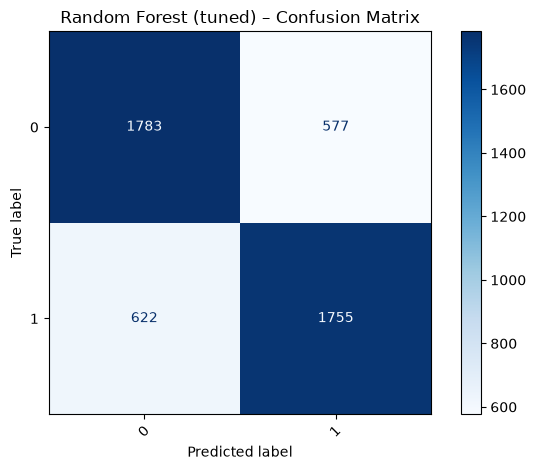

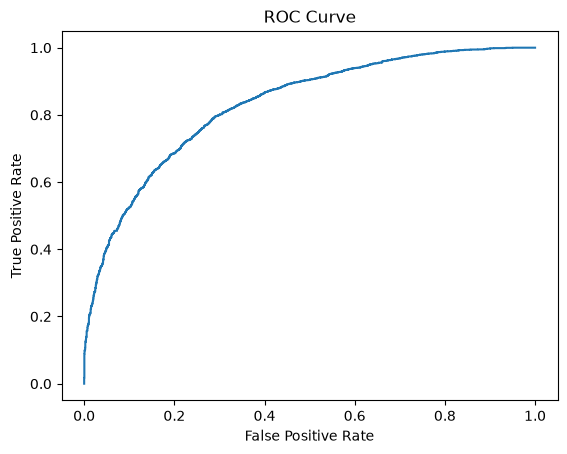

AUC: 0.8301754811291828


In [21]:
print("Accuracy:", accuracy_score(y_test, y_pred_tunedRF))
print(classification_report(y_test, y_pred_tunedRF))

plt.figure(figsize=(7,5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tunedRF,
    xticks_rotation=45,
    cmap="Blues"
)
plt.title("Random Forest (tuned) – Confusion Matrix")
plt.tight_layout()
plt.show()


y_prob = model_tunedRF.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

print("AUC:", roc_auc_score(y_test, y_prob))

This model already reaches a fairly good result.
* Accuracy: 74.69% – the best of all models compared so far, though only slightly above the baseline Random Forest (74.10%).
* Precision & Recall: very similar for both classes (0.74–0.76), so the model handles both classes without a noticeable imbalance.
* F1-score: 0.75 for both classes, confirming consistent classification.
* AUC: 0.830 – excellent class separation, which is key for binary classification.
* Best CV accuracy: 75.9% – confirms that the model is stable under cross-validation.

Best parameters:
* n_estimators: 200
* min_samples_split: 5
* min_samples_leaf: 4
* max_features: sqrt
* max_depth: 10
* criterion: entropy
* bootstrap: False

# Logistic Regression

Not to be confused with linear regression, which predicts an unbounded continuous value. Logistic regression is a classifier: it passes a linear combination of the features through the **sigmoid function**, which squashes the result into a probability between 0 and 1, and then assigns class 0 or 1.

## Logistic Regression: Baseline

In [22]:
model_baseLR = LogisticRegression(random_state=42)
model_baseLR.fit(X_train_scaled, y_train)

y_pred_baseLR = model_baseLR.predict(X_test_scaled)

Accuracy: 0.7523749208359721
              precision    recall  f1-score   support

           0       0.75      0.76      0.75      2360
           1       0.76      0.75      0.75      2377

    accuracy                           0.75      4737
   macro avg       0.75      0.75      0.75      4737
weighted avg       0.75      0.75      0.75      4737



<Figure size 700x500 with 0 Axes>

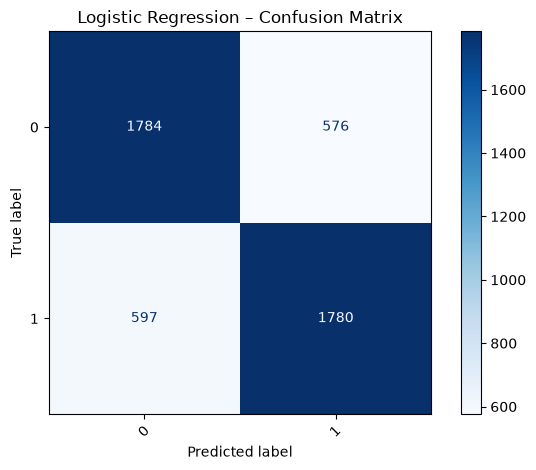

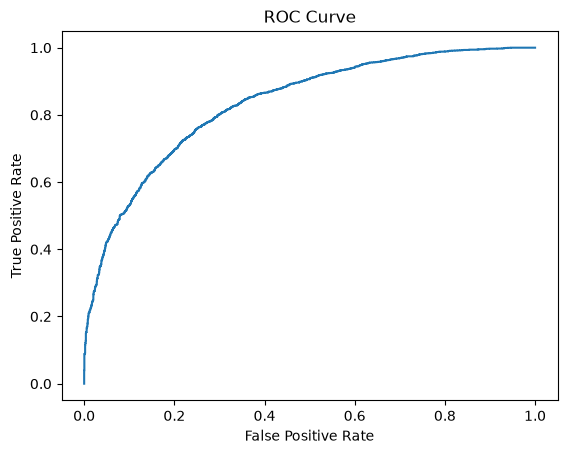

AUC: 0.8336218206969331


In [23]:
print("Accuracy:", accuracy_score(y_test, y_pred_baseLR))
print(classification_report(y_test, y_pred_baseLR))

plt.figure(figsize=(7,5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_baseLR,
    xticks_rotation=45,
    cmap="Blues"
)
plt.title("Logistic Regression – Confusion Matrix")
plt.tight_layout()
plt.show()


y_prob = model_baseLR.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

print("AUC:", roc_auc_score(y_test, y_prob))

The baseline logistic regression slightly outperforms even the tuned Random Forest.
* Accuracy: 75.24% – above the tuned Random Forest (74.69%), a surprisingly strong result for such a simple model.
* Precision & Recall: very balanced across classes (0.75–0.76), so the model handles both classes without noticeable bias.
* F1-score: 0.75 for both classes, confirming consistent performance.
* AUC: 0.834 – excellent class separation, comparable to the tuned Random Forest.

## Logistic Regression: Tuning

| Parameter        | Meaning                                           | Effect                                               |
|-----------------|-------------------------------------------------|---------------------------------------------------|
| penalty         | Regularization type ('l2', 'l1', 'elasticnet', 'none') | Affects overfitting and feature selection           |
| C               | Inverse regularization strength (e.g. 0.01, 1, 100)   | Smaller C = stronger regularization                  |
| solver          | Optimization algorithm ('lbfgs', 'liblinear', 'saga', 'newton-cg') | Affects speed and which penalties are supported        |
| max_iter        | Maximum number of iterations                           | Helps with convergence                           |
| class_weight    | Class weights (None, 'balanced', or a dict)       | Helps with imbalanced classes                 |
| fit_intercept   | Add an intercept (True/False)                   | Affects the decision boundary           |
| multi_class     | Classification scheme ('auto', 'ovr', 'multinomial')  | Relevant for more than two classes                    |
| random_state    | Seed for reproducibility                      | Ensures consistent results                            |


In [24]:
param_grid_LR = {
    'penalty': ['l1', 'l2'],
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['liblinear', 'saga'],
    'class_weight': [None, 'balanced'],
    'max_iter': [100, 500, 1000]
}



clf_LR = LogisticRegression(random_state=42)
model_tunedLR = RandomizedSearchCV(estimator=clf_LR, param_distributions=param_grid_LR, n_iter=30, cv=5, scoring='accuracy', n_jobs=-1, random_state=42)
model_tunedLR.fit(X_train_scaled, y_train)

print("Best parameters:", model_tunedLR.best_params_)
print("Best CV accuracy:", model_tunedLR.best_score_)

y_pred_tunedLR = model_tunedLR.predict(X_test_scaled)

Best parameters: {'solver': 'saga', 'penalty': 'l2', 'max_iter': 1000, 'class_weight': None, 'C': 0.01}
Best CV accuracy: 0.7600272278244691


Accuracy: 0.7515305045387376
              precision    recall  f1-score   support

           0       0.75      0.76      0.75      2360
           1       0.75      0.75      0.75      2377

    accuracy                           0.75      4737
   macro avg       0.75      0.75      0.75      4737
weighted avg       0.75      0.75      0.75      4737



<Figure size 700x500 with 0 Axes>

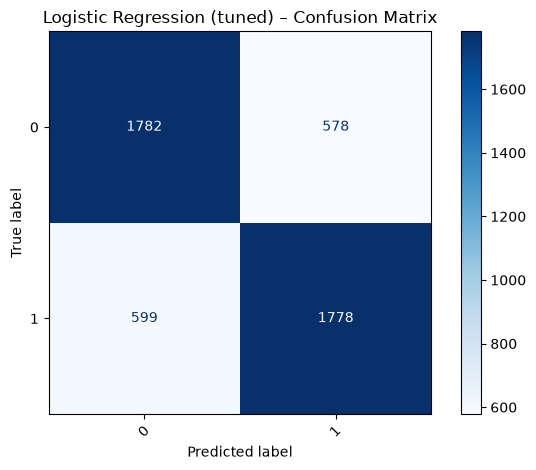

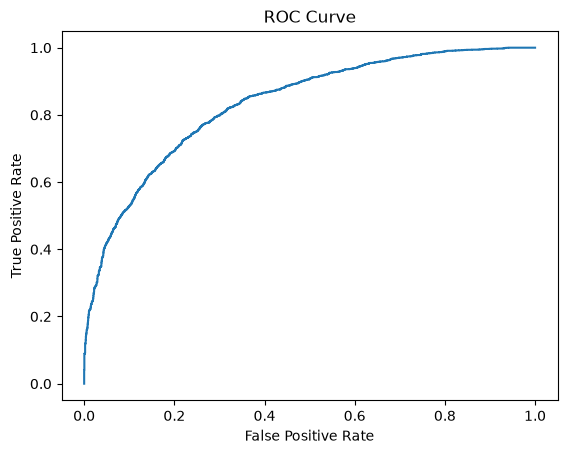

AUC: 0.833118230499918


In [25]:
print("Accuracy:", accuracy_score(y_test, y_pred_tunedLR))
print(classification_report(y_test, y_pred_tunedLR))

plt.figure(figsize=(7,5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tunedLR,
    xticks_rotation=45,
    cmap="Blues"
)
plt.title("Logistic Regression (tuned) – Confusion Matrix")
plt.tight_layout()
plt.show()


y_prob = model_tunedLR.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

print("AUC:", roc_auc_score(y_test, y_prob))

The tuned logistic regression performs surprisingly well, on par with the best models tested so far.
* Accuracy: 75.15% – almost identical to the baseline logistic regression (75.24%) and slightly above the tuned Random Forest (74.69%). Tuning brings no gain on the test set.
* Precision & Recall: very balanced across classes (0.75–0.76), so the model handles both classes well.
* F1-score: 0.75 for both classes, confirming consistent classification.
* AUC: 0.833 – excellent class separation, on par with the best models in this comparison.
* Best CV accuracy: 76.0% – confirms the model is stable under cross-validation.

# XGBoost

XGBoost is a powerful gradient boosting algorithm: it builds trees sequentially, with each new tree correcting the errors of the previous ones. It is well suited to complex numerical datasets and often achieves state-of-the-art results.

## XGBoost: Baseline

In [26]:
model_baseXGB = XGBClassifier(random_state=42, eval_metric='logloss')
model_baseXGB.fit(X_train_scaled, y_train)

y_pred_baseXGB = model_baseXGB.predict(X_test_scaled)

Accuracy: 0.73569769896559
              precision    recall  f1-score   support

           0       0.73      0.74      0.74      2360
           1       0.74      0.73      0.74      2377

    accuracy                           0.74      4737
   macro avg       0.74      0.74      0.74      4737
weighted avg       0.74      0.74      0.74      4737



<Figure size 700x500 with 0 Axes>

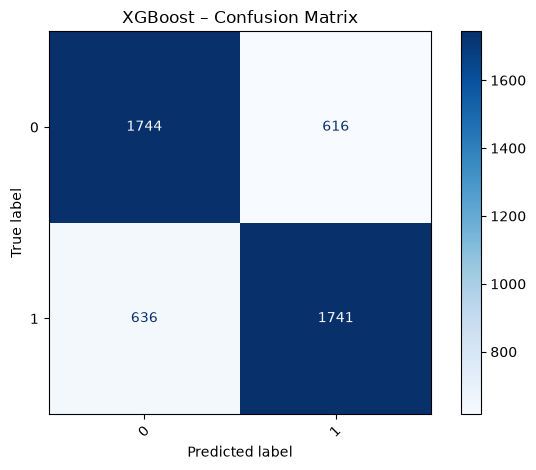

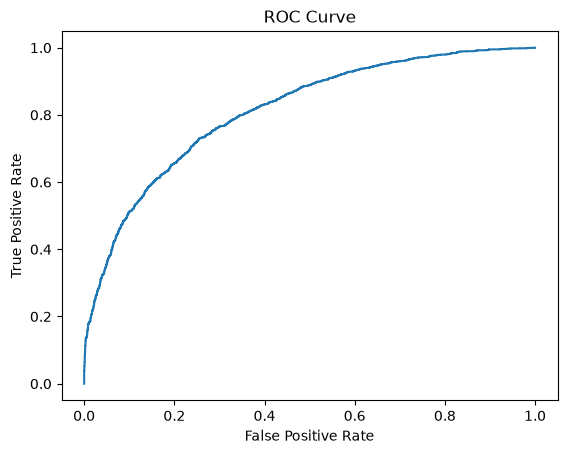

AUC: 0.8119966771960098


In [27]:
print("Accuracy:", accuracy_score(y_test, y_pred_baseXGB))
print(classification_report(y_test, y_pred_baseXGB))

plt.figure(figsize=(7,5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_baseXGB,
    xticks_rotation=45,
    cmap="Blues"
)
plt.title("XGBoost – Confusion Matrix")
plt.tight_layout()
plt.show()


y_prob = model_baseXGB.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

print("AUC:", roc_auc_score(y_test, y_prob))

The baseline XGBoost model shows solid performance on these metrics, although it is not yet among the very best models in this comparison.
* Accuracy: 73.57% – lower than the tuned Random Forest or logistic regression, but still competitive.
* Precision & Recall: balanced across classes (0.73–0.74), so the model handles both classes well.
* F1-score: 0.74 for both classes, confirming consistent classification.
* AUC: 0.812 – very good class separation, clearly better than the baseline decision tree and slightly above the tuned tree (0.801).

## XGBoost: Tuning

| Parameter           | Description                                              | Recommended values                          |
|-------------------|---------------------------------------------------|---------------------------------------------|
| n_estimators       | Number of trees                                      | [100, 200, 300, 500]                        |
| max_depth          | Maximum tree depth                          | [3, 5, 7, 10]                               |
| learning_rate      | Learning rate                                    | [0.01, 0.05, 0.1, 0.2]                      |
| subsample          | Fraction of training data used for each tree            | [0.6, 0.8, 1.0]                             |
| colsample_bytree   | Fraction of features used for each tree                 | [0.6, 0.8, 1.0]                             |
| gamma              | Minimum loss reduction required to split a node               | [0, 0.1, 0.2, 0.5]                          |
| reg_alpha          | L1 regularization (sparse model)                   | [0, 0.1, 1]                                 |
| reg_lambda         | L2 regularization (Ridge)                           | [0.1, 1, 10]                                |
| scale_pos_weight   | Weight of the positive class (useful for imbalanced data) | [1, 2, 5]                    |
| objective          | Learning task                                        | 'binary:logistic'                            |
| eval_metric        | Evaluation metric                             | 'logloss', 'error', 'auc'                    |


In [28]:
param_grid_XGB = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'gamma': [0, 0.1],
    'reg_alpha': [0, 0.1],
    'reg_lambda': [1, 10],
    'scale_pos_weight': [1, 2],
}



clf_XGB = XGBClassifier(random_state=42)
model_tunedXGB = RandomizedSearchCV(estimator=clf_XGB, param_distributions=param_grid_XGB, n_iter=30, cv=5, scoring='accuracy', n_jobs=-1, random_state=42)
model_tunedXGB.fit(X_train_scaled, y_train)

print("Best parameters:", model_tunedXGB.best_params_)
print("Best CV accuracy:", model_tunedXGB.best_score_)

y_pred_tunedXGB = model_tunedXGB.predict(X_test_scaled)

Best parameters: {'subsample': 1.0, 'scale_pos_weight': 1, 'reg_lambda': 1, 'reg_alpha': 0.1, 'n_estimators': 100, 'max_depth': 3, 'learning_rate': 0.1, 'gamma': 0, 'colsample_bytree': 0.8}
Best CV accuracy: 0.7613465029654652


Accuracy: 0.746675110829639
              precision    recall  f1-score   support

           0       0.74      0.75      0.75      2360
           1       0.75      0.74      0.75      2377

    accuracy                           0.75      4737
   macro avg       0.75      0.75      0.75      4737
weighted avg       0.75      0.75      0.75      4737



<Figure size 700x500 with 0 Axes>

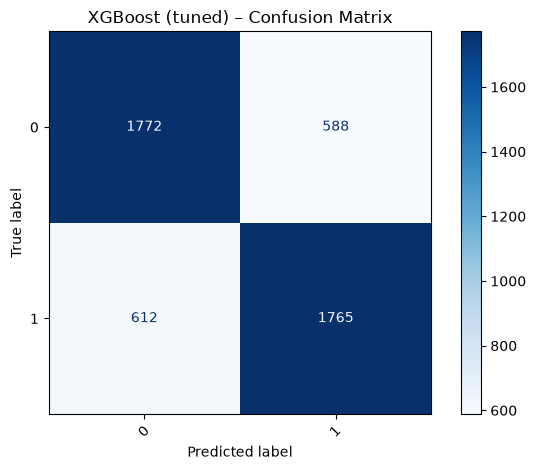

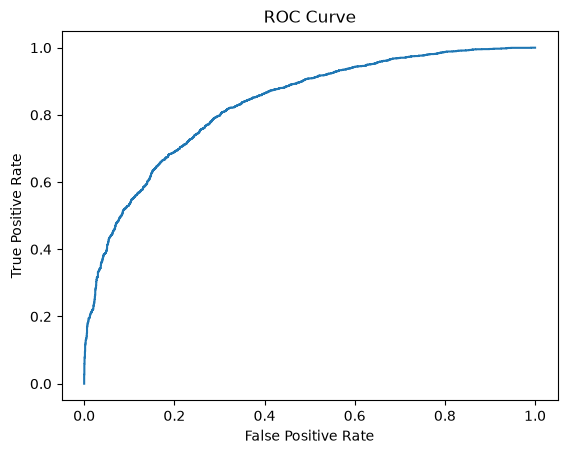

AUC: 0.8309541296178775


In [29]:
print("Accuracy:", accuracy_score(y_test, y_pred_tunedXGB))
print(classification_report(y_test, y_pred_tunedXGB))

plt.figure(figsize=(7,5))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_tunedXGB,
    xticks_rotation=45,
    cmap="Blues"
)
plt.title("XGBoost (tuned) – Confusion Matrix")
plt.tight_layout()
plt.show()


y_prob = model_tunedXGB.predict_proba(X_test_scaled)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.show()

print("AUC:", roc_auc_score(y_test, y_prob))

Based on these results, the tuned XGBoost model is among the best models tested.
* Accuracy: 74.67% – almost identical to the tuned Random Forest (74.69%) and slightly below logistic regression (75.15–75.24%).
* Precision & Recall: very balanced across classes (0.74–0.75), so the model handles both classes well.
* F1-score: 0.75 for both classes, confirming consistent classification.
* AUC: 0.831 – excellent class separation, on par with the best models in this comparison.
* Best CV accuracy: 76.13% – the highest cross-validation accuracy of all models, confirming the model is stable.

Best parameters:
* n_estimators: 100
* max_depth: 3
* learning_rate: 0.1
* subsample: 1.0
* colsample_bytree: 0.8
* gamma: 0
* reg_alpha: 0.1
* reg_lambda: 1
* scale_pos_weight: 1

# Summary

The goal of this project was to analyze a real-world dataset, prepare it for modeling, compare four classification algorithms, tune the hyperparameters of each one, and evaluate the results.

### Data Preprocessing
As described in the introduction, the dataset contains in-game statistics from the first 15 minutes of individual ranked League of Legends matches. The task of the classifiers was to predict, from these first 15 minutes, which team wins. The dataset itself was well distributed and highly informative, so the features needed almost no modification, with the exception of the turret plate columns (see Data Preprocessing) and the matchID column, which was dropped.

For feature scaling I used a `ColumnTransformer` with `StandardScaler` for the roughly Gaussian features and `RobustScaler` for the skewed features with outliers.

The data was then split into training and test sets in an 80/20 ratio with stratification.

### Classification Algorithms
The first two models were a Decision Tree and a Random Forest. A decision tree's rules are easy to visualize and the model is simple to understand, but it is prone to overfitting and performs worse than ensemble methods. The decision tree alone did not give convincing results; they improved only after hyperparameter optimization. The untuned Random Forest already beat the tuned decision tree, and tuning did not change much. Its advantages are simplicity and, unlike a single decision tree, lower sensitivity to overfitting even without tuning. Its drawback is that hyperparameter tuning was the slowest of all models.

I then added Logistic Regression and XGBoost. Logistic regression was chosen because it is designed for exactly this kind of binary decision (here, a blue or red team win). Its strength is again simplicity: it computes a linear combination of all input features and passes it through the sigmoid function, which returns the probability that a sample belongs to the positive class. XGBoost was chosen for its performance and its reputation as one of the strongest classification models. It builds many small trees, each one correcting the errors of the previous ones. Without hyperparameter optimization it did not reach convincing results and needed tuning. After tuning it performed very well, matching the tuned Random Forest on the test set and coming close to logistic regression.


*All models were tuned with **RandomizedSearchCV**, which made the hyperparameter search much faster. The speed-up paid off especially for the Random Forest.*


### Results

| Model             | Baseline accuracy | Tuned accuracy | AUC (tuned) | Notes                                 |
|----------------------|----------------------|------------------------|----------------|----------------------------------------------|
| Decision Tree        | 0.669                | 0.726                  | 0.801          | Large improvement after limiting tree depth         |
| Random Forest        | 0.741                | 0.747                  | 0.830          | Stable performance, slight improvement after tuning    |
| Logistic Regression  | 0.752                | 0.752                  | 0.833          | Strong performance even without tuning, highly interpretable |
| XGBoost              | 0.736                | 0.747                  | 0.831          | Powerful model, tuning helped noticeably        |

**Logistic Regression** achieved the best test accuracy (0.752, both with and without tuning). In terms of AUC, i.e. how well the models separate the two classes (true positive rate vs. false positive rate), **Logistic Regression** is again the best (0.833 tuned, 0.834 baseline), closely followed by **XGBoost** (0.831) and **Random Forest** (0.830). Tuned XGBoost had the highest cross-validation accuracy (0.761, vs. 0.760 for tuned logistic regression), so the top three models are practically tied.
